# Chapter 5

### Chapter 5 Exercise 4

D is 500 x 2
v1: [-0.86739358 -0.49762272]
v2: [-0.49762272  0.86739358]
variances: [3.66589325 0.10993305]
variance explained by v1: 0.9708850359165098


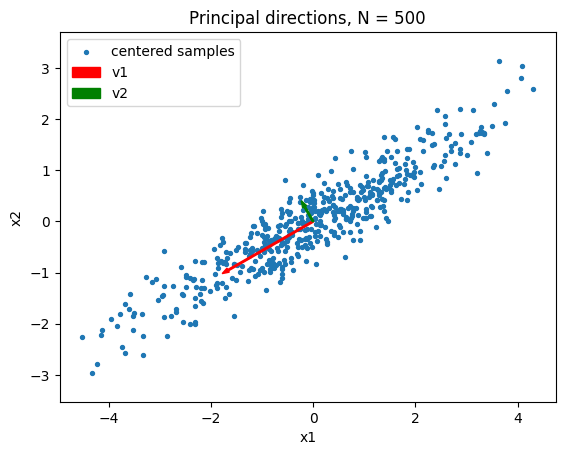

seed 352 N = 50, angle of v1: 31.56474315954983
seed 353 N = 50, angle of v1: 30.16374049488298
seed 354 N = 50, angle of v1: 30.753201529500952


In [39]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(352)
N = 500
Sigma = np.array([[3, 1.6], [1.6, 1]])
D = rng.multivariate_normal([0, 0], Sigma, N)
print("D is", D.shape[0], "x", D.shape[1])

X = D - D.mean(axis=0)
U, s, Vt = np.linalg.svd(X, full_matrices=False)
V = Vt.T

variances = s**2 / (N - 1)
print("v1:", V[:, 0])
print("v2:", V[:, 1])
print("variances:", variances)
print("variance explained by v1:", variances[0] / np.sum(variances))

std = s / np.sqrt(N - 1)
plt.scatter(X[:, 0], X[:, 1], s=8, label="centered samples")
plt.arrow(0, 0, std[0]*V[0, 0], std[0]*V[1, 0], color="red", width=0.03, label="v1")
plt.arrow(0, 0, std[1]*V[0, 1], std[1]*V[1, 1], color="green", width=0.03, label="v2")
plt.axis('equal')
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Principal directions, N = 500")
plt.legend()
plt.show()

for seed in [352, 353, 354]:
  rng = np.random.default_rng(seed)
  D = rng.multivariate_normal([0, 0], Sigma, 50)
  X = D - D.mean(axis=0)
  U, s, Vt = np.linalg.svd(X, full_matrices=False)
  angle = np.degrees(np.arctan(Vt[0, 1] / Vt[0, 0]))
  print("seed", seed, "N = 50, angle of v1:", angle)

$v_1$ matched the expected value of $(0.88, 0.47)$, but with flipped signs. The variance explained by $v_1$ was about 97.1%. When N=50, the angle was different with each seed used. The fewer samples gave a direction that was less reliable.

### Chapter 5 Exercise 5

X is 201 x 120
energy fractions (%): [49.87 30.57 14.03  3.75  1.36  0.36]
modes to reach 99%: 5


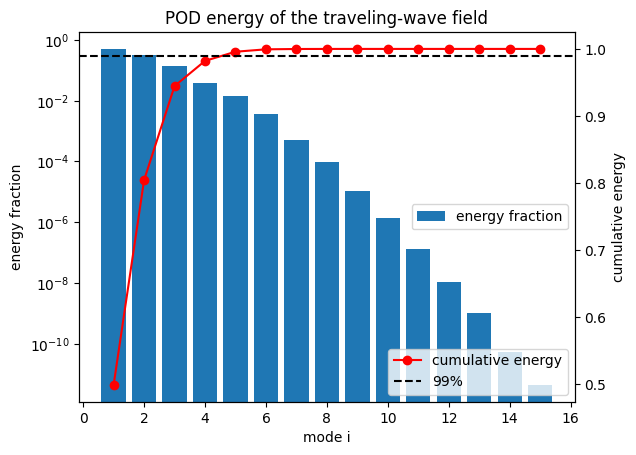

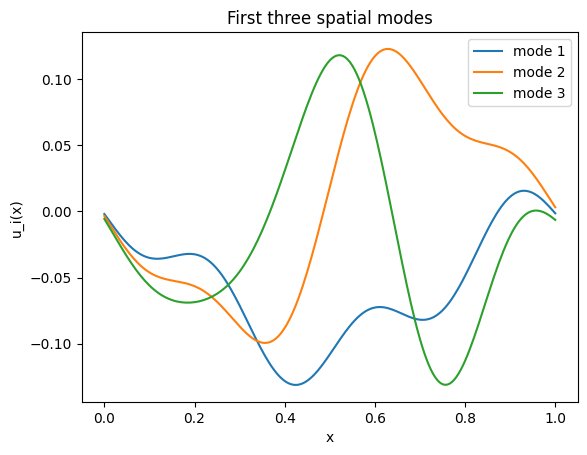

In [40]:
import numpy as np
import matplotlib.pyplot as plt

w = 0.10
c = 0.6
A = 0.4
tau = 0.25
kappa = 3

x = np.linspace(0, 1, 201)
t = np.linspace(0, 1, 120)

X = np.zeros((201, 120))
for j in range(120):
  X[:, j] = np.exp(-(x - 0.2 - c*t[j])**2 / (2*w**2)) + A*np.exp(-t[j]/tau)*np.sin(2*np.pi*kappa*x)
print("X is", X.shape[0], "x", X.shape[1])

U, s, Vt = np.linalg.svd(X, full_matrices=False)
energy = s**2 / np.sum(s**2)
cumulative = np.cumsum(energy)
print("energy fractions (%):", np.round(100*energy[:6], 2))

k99 = 0
while cumulative[k99] < 0.99:
  k99 += 1
print("modes to reach 99%:", k99 + 1)

fig, ax1 = plt.subplots()
modes = np.arange(1, 16)
ax1.bar(modes, energy[:15], label="energy fraction")
ax1.set_yscale('log')
ax1.set_xlabel("mode i")
ax1.set_ylabel("energy fraction")
ax2 = ax1.twinx()
ax2.plot(modes, cumulative[:15], 'r-o', label="cumulative energy")
ax2.axhline(0.99, color='k', linestyle='--', label="99%")
ax2.set_ylabel("cumulative energy")
ax1.legend(loc="center right")
ax2.legend(loc="lower right")
plt.title("POD energy of the traveling-wave field")
plt.show()

for i in range(3):
  plt.plot(x, U[:, i], label="mode " + str(i+1))
plt.xlabel("x")
plt.ylabel("u_i(x)")
plt.title("First three spatial modes")
plt.legend()
plt.show()

5 different modes were used to reach 99% because moving waves need multiple different modes, not just one. Mode 1 is the average shape of the pulse, and modes 2 and 3 are shifted copies of each other, which is the pair that moves the pulse. None of the first three is a clean standing wave; its wiggles are mixed into all three because it only carries about 5.5% of the energy.

### Chapter 5 Exercise 6

X is 569 x 30


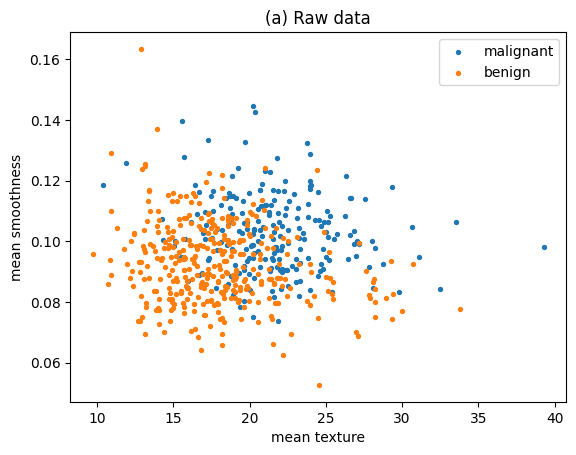

(a) correlation: -0.023388515998423603
(a) best accuracy, mean texture: 0.7363796133567663
(a) best accuracy, mean smoothness: 0.680140597539543


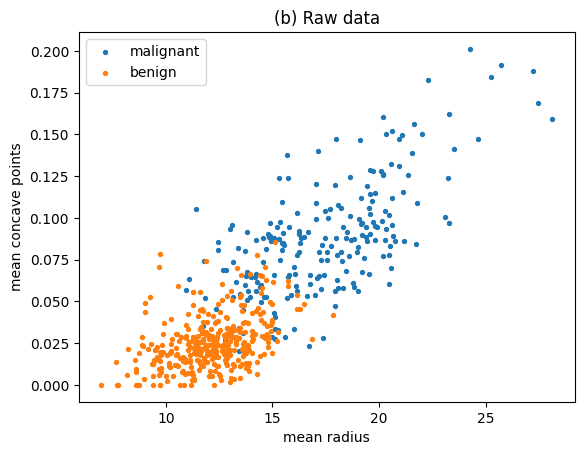

(b) correlation: 0.8225285223871797
(b) best accuracy, mean radius: 0.8910369068541301
(b) best accuracy, mean concave points: 0.9156414762741653


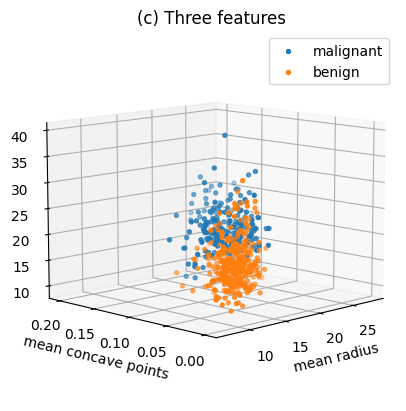

(c) variance captured by first two PCs: 0.9410593942075149
(d) best single feature: worst radius 0.9226713532513181


In [41]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = data.data
y = data.target
names = data.feature_names
print("X is", X.shape[0], "x", X.shape[1])

def best_acc(f, y):
  best = 0
  for c in np.unique(f):
    pred = (f > c)
    acc = max(np.mean(pred == y), np.mean(pred != y))
    if acc > best:
      best = acc
  return best

def col(name):
  return X[:, list(names).index(name)]

# (a)
f1 = col("mean texture")
f2 = col("mean smoothness")
plt.scatter(f1[y == 0], f2[y == 0], s=8, label="malignant")
plt.scatter(f1[y == 1], f2[y == 1], s=8, label="benign")
plt.xlabel("mean texture")
plt.ylabel("mean smoothness")
plt.title("(a) Raw data")
plt.legend()
plt.show()
print("(a) correlation:", np.corrcoef(f1, f2)[0, 1])
print("(a) best accuracy, mean texture:", best_acc(f1, y))
print("(a) best accuracy, mean smoothness:", best_acc(f2, y))

# (b)
g1 = col("mean radius")
g2 = col("mean concave points")
plt.scatter(g1[y == 0], g2[y == 0], s=8, label="malignant")
plt.scatter(g1[y == 1], g2[y == 1], s=8, label="benign")
plt.xlabel("mean radius")
plt.ylabel("mean concave points")
plt.title("(b) Raw data")
plt.legend()
plt.show()
print("(b) correlation:", np.corrcoef(g1, g2)[0, 1])
print("(b) best accuracy, mean radius:", best_acc(g1, y))
print("(b) best accuracy, mean concave points:", best_acc(g2, y))

# (c)
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(g1[y == 0], g2[y == 0], f1[y == 0], s=8, label="malignant")
ax.scatter(g1[y == 1], g2[y == 1], f1[y == 1], s=8, label="benign")
ax.set_xlabel("mean radius")
ax.set_ylabel("mean concave points")
ax.set_zlabel("mean texture")
ax.view_init(elev=10, azim=-135)
plt.title("(c) Three features")
plt.legend()
plt.show()

Y = np.column_stack([g1, g2, f1])
Z3 = (Y - Y.mean(axis=0)) / Y.std(axis=0, ddof=0)
U, s, Vt = np.linalg.svd(Z3, full_matrices=False)
print("(c) variance captured by first two PCs:", np.sum(s[:2]**2) / np.sum(s**2))

# (d)
accs = np.zeros(30)
for j in range(30):
  accs[j] = best_acc(X[:, j], y)
best = np.argmax(accs)
print("(d) best single feature:", names[best], accs[best])

(a)
The features are mostly uncorrelated and do not separate the classes well.

(b)
The radius and concave points are strongly correlated, so they increase together.

(c)
The 3D view appears to be congregated in a flat sheet like pattern. This confirms the variance is mostly in 2 directions.

(d)
The worst radius beating PC1 is because PCA doesn't use labels. It only finds directions of most variance. The best single feature was chosen using labels and PC1 was close. PC1 would win if direction where data spreads the most was direction that separates malignant and benign.

### Chapter 5 Exercise 7

X is 569 x 30
(a) explained variance (%): [44.3 19.   9.4  6.6  5.5  4. ]
(a) first k to cross 95%: 10
(c) accuracy with threshold at -0.6: 0.9156414762741653


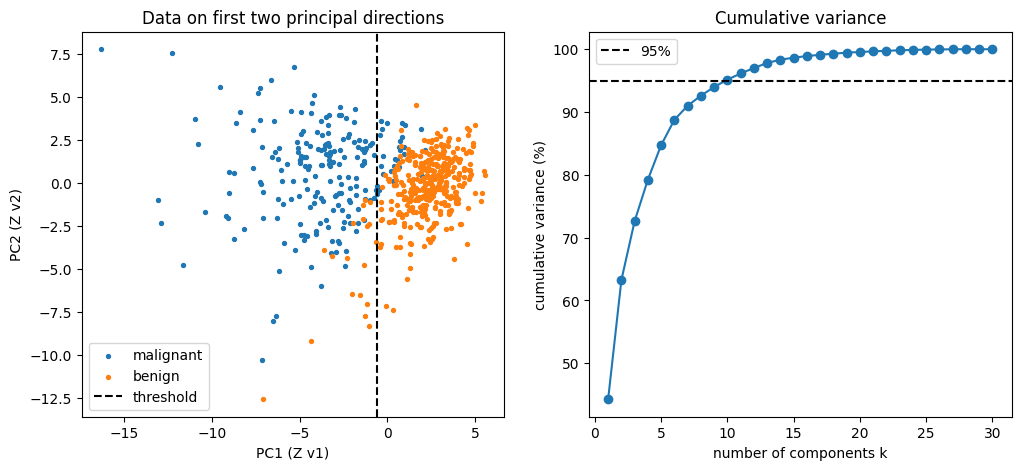

(d) six largest |v1| loadings:
mean concave points -0.2608537583857403
mean concavity -0.25840048124877146
worst concave points -0.25088597121799705
mean compactness -0.2392853539530008
worst perimeter -0.23663968074164496
worst concavity -0.22876753281500928


In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = data.data
y = data.target
names = data.feature_names
print("X is", X.shape[0], "x", X.shape[1])

Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=0)
U, s, Vt = np.linalg.svd(Z, full_matrices=False)
V = Vt.T

explained = s**2 / np.sum(s**2)
cumulative = np.cumsum(explained)
print("(a) explained variance (%):", np.round(100*explained[:6], 1))
k95 = 0
while cumulative[k95] < 0.95:
  k95 += 1
print("(a) first k to cross 95%:", k95 + 1)

v1 = V[:, 0]
v2 = V[:, 1]
pc1 = Z @ v1
pc2 = Z @ v2

if np.mean(pc1[y == 0]) > np.mean(pc1[y == 1]):
  v1 = -v1
  pc1 = -pc1

pred = (pc1 > -0.6)
acc = np.mean(pred == y)
print("(c) accuracy with threshold at -0.6:", acc)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(pc1[y == 0], pc2[y == 0], s=8, label="malignant")
plt.scatter(pc1[y == 1], pc2[y == 1], s=8, label="benign")
plt.axvline(-0.6, color='k', linestyle='--', label="threshold")
plt.xlabel("PC1 (Z v1)")
plt.ylabel("PC2 (Z v2)")
plt.title("Data on first two principal directions")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(np.arange(1, 31), 100*cumulative, 'o-')
plt.axhline(95, color='k', linestyle='--', label="95%")
plt.xlabel("number of components k")
plt.ylabel("cumulative variance (%)")
plt.title("Cumulative variance")
plt.legend()
plt.show()

order = np.argsort(np.abs(v1))[::-1]
print("(d) six largest |v1| loadings:")
for j in order[:6]:
  print(names[j], v1[j])

PC1 separates classes as good as the best single feature. k=10 is needed to cross 95%, so variance is spread beyond the first few PCs. The six features with the largest loadings share concavity and size features, so PC1 mostly measures tumor shape and size.

### Chapter 5 Exercise 8

grid 60 x 60 , n = 3600 , steps = 200
snapshot matrices: (3600, 200) (3600, 200)
modes for 0.95 : stationary 1 , moving 3
modes for 0.99 : stationary 1 , moving 5
modes for 0.999 : stationary 2 , moving 9
rank-1 relative error, stationary: 0.08319368692781225
rank-1 relative error, moving: 0.45658369670749166


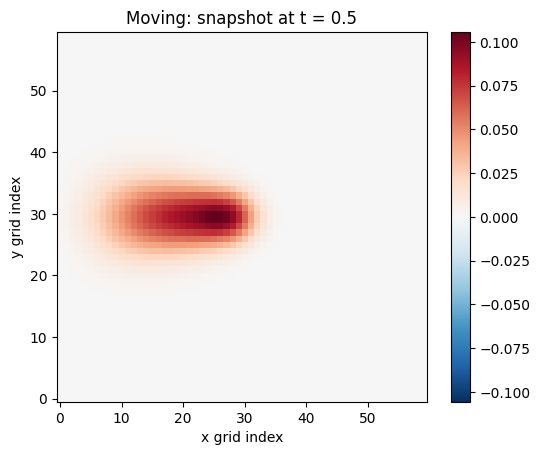

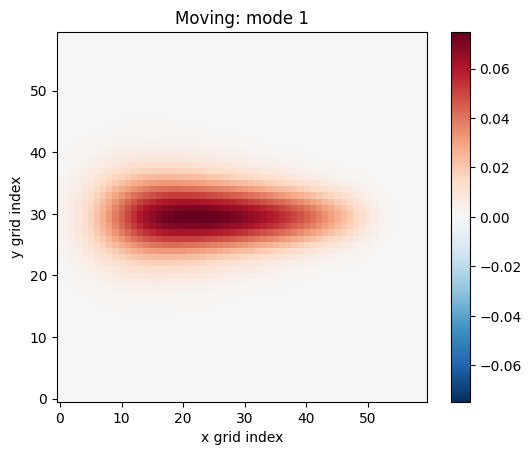

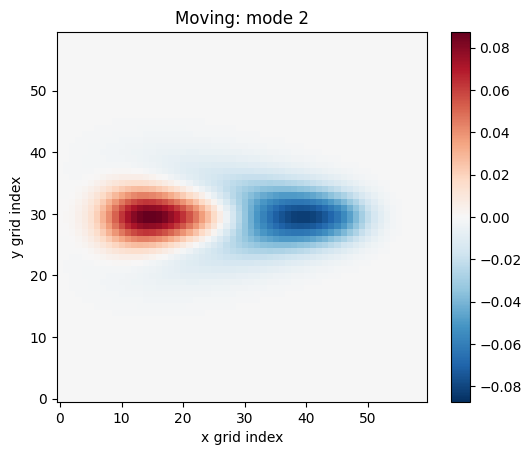

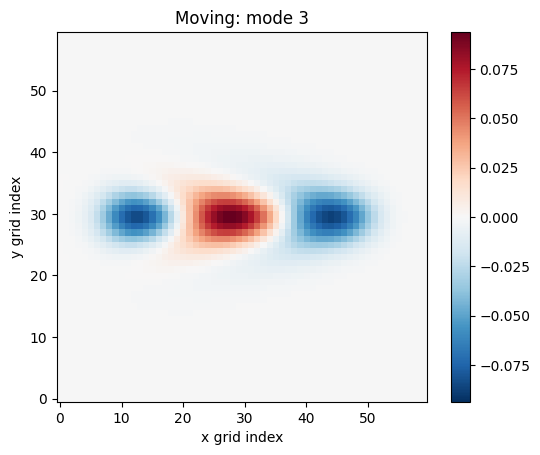

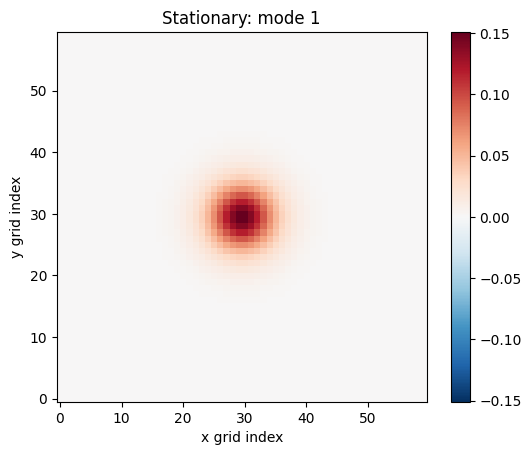

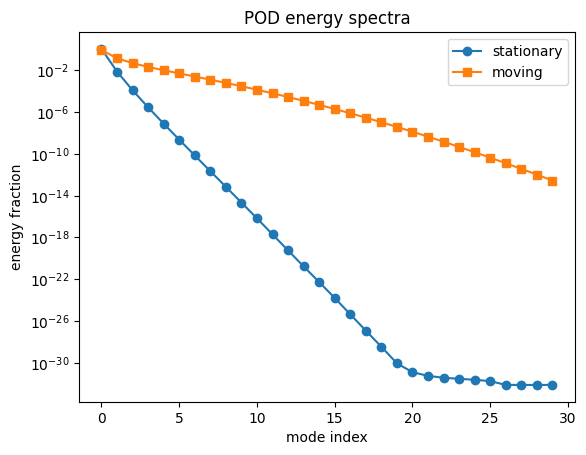

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.linalg import splu

alpha = 0.005
s_w = 0.04
P = 1
cy = 0.5
Tend = 1
nx = 60
h = 1 / 61
n = nx * nx
steps = 200
dt = Tend / steps
print("grid", nx, "x", nx, ", n =", n, ", steps =", steps)

grid = np.linspace(h, 1 - h, nx)
xx, yy = np.meshgrid(grid, grid, indexing='ij')
xv = xx.flatten()
yv = yy.flatten()

D = sp.diags([np.ones(nx-1), -2*np.ones(nx), np.ones(nx-1)], [-1, 0, 1]) / h**2
I = sp.identity(nx)
L = sp.kron(D, I) + sp.kron(I, D)

M = sp.identity(n) - dt * alpha * L
solver = splu(M.tocsc())

def run(moving):
  T = np.zeros(n)
  snaps = np.zeros((n, steps))
  for k in range(steps):
    t = (k + 1) * dt
    if moving:
      cx = 0.15 + 0.7 * t / Tend
    else:
      cx = 0.5
    q = P * np.exp(-((xv - cx)**2 + (yv - cy)**2) / (2 * s_w**2))
    T = solver.solve(T + dt * q)
    snaps[:, k] = T
  return snaps

Xs = run(False)
Xm = run(True)
print("snapshot matrices:", Xs.shape, Xm.shape)

Us, ss, _ = np.linalg.svd(Xs, full_matrices=False)
Um, sm, _ = np.linalg.svd(Xm, full_matrices=False)

def count(s, level):
  cum = np.cumsum(s**2) / np.sum(s**2)
  k = 0
  while cum[k] < level:
    k += 1
  return k + 1

for level in [0.95, 0.99, 0.999]:
  print("modes for", level, ": stationary", count(ss, level), ", moving", count(sm, level))

print("rank-1 relative error, stationary:", np.sqrt(np.sum(ss[1:]**2) / np.sum(ss**2)))
print("rank-1 relative error, moving:", np.sqrt(np.sum(sm[1:]**2) / np.sum(sm**2)))

def show(u, title):
  if u[np.argmax(np.abs(u))] < 0:
    u = -u
  m = np.max(np.abs(u))
  plt.imshow(u.reshape(nx, nx).T, origin='lower', cmap='RdBu_r', vmin=-m, vmax=m)
  plt.colorbar()
  plt.xlabel("x grid index")
  plt.ylabel("y grid index")
  plt.title(title)
  plt.show()

show(Xm[:, 99], "Moving: snapshot at t = 0.5")
show(Um[:, 0], "Moving: mode 1")
show(Um[:, 1], "Moving: mode 2")
show(Um[:, 2], "Moving: mode 3")
show(Us[:, 0], "Stationary: mode 1")

plt.semilogy(ss[:30]**2 / np.sum(ss**2), 'o-', label="stationary")
plt.semilogy(sm[:30]**2 / np.sum(sm**2), 's-', label="moving")
plt.xlabel("mode index")
plt.ylabel("energy fraction")
plt.title("POD energy spectra")
plt.legend()
plt.show()

The stationary needs 1 or 2 modes, while moving needs a good bit more. This is because the stationary field keeps its shape, instead the moving field changes shape. This is why the stationary energy curve drops off quickly and the moving energy curve levels out slowly.

### Chapter 5 Exercise 25

L is 150 x 150 , rank 3
eta = 0.01  s3 = 3.011  s4 = 0.24  ||Xk-L|| = 0.143  2||N|| = 0.486  ratio = 0.587
eta = 0.02  s3 = 3.033  s4 = 0.479  ||Xk-L|| = 0.286  2||N|| = 0.972  ratio = 0.589
eta = 0.05  s3 = 3.156  s4 = 1.197  ||Xk-L|| = 0.751  2||N|| = 2.43  ratio = 0.618
eta = 0.1  s3 = 3.566  s4 = 2.391  ||Xk-L|| = 1.726  2||N|| = 4.861  ratio = 0.71
eta = 0.15  s3 = 4.243  s4 = 3.581  ||Xk-L|| = 3.007  2||N|| = 7.291  ratio = 0.825
eta = 0.2  s3 = 5.164  s4 = 4.764  ||Xk-L|| = 4.447  2||N|| = 9.722  ratio = 0.915
eta = 0.25  s3 = 6.236  s4 = 5.947  ||Xk-L|| = 5.834  2||N|| = 12.152  ratio = 0.96
eta = 0.3  s3 = 7.375  s4 = 7.142  ||Xk-L|| = 7.141  2||N|| = 14.583  ratio = 0.979
eta = 0.4  s3 = 9.688  s4 = 9.533  ||Xk-L|| = 9.646  2||N|| = 19.443  ratio = 0.992
eta = 0.5  s3 = 11.94  s4 = 11.862  ||Xk-L|| = 12.128  2||N|| = 24.304  ratio = 0.998


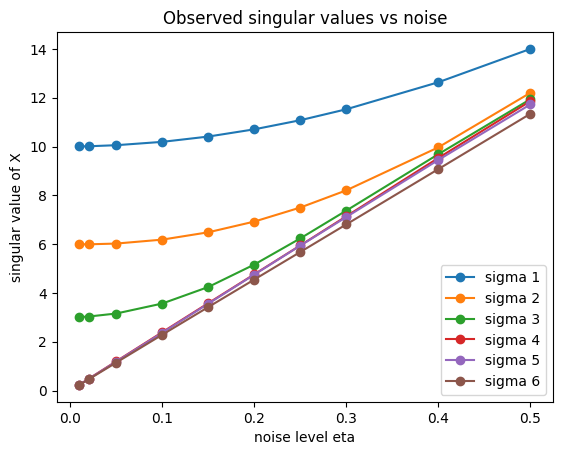

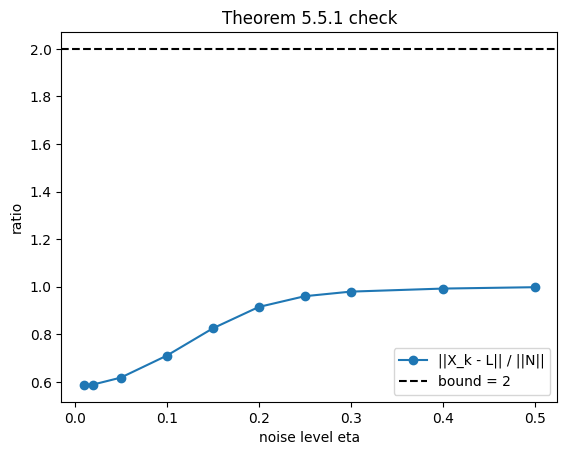

In [44]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(352)
m = 150
n = 150
k = 3

U0, _ = np.linalg.qr(rng.standard_normal((m, k)))
V0, _ = np.linalg.qr(rng.standard_normal((n, k)))
L = U0 @ np.diag([10, 6, 3]) @ V0.T
print("L is", m, "x", n, ", rank", np.linalg.matrix_rank(L))

G = rng.standard_normal((m, n))

etas = [0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
sig = np.zeros((len(etas), 6))
ratios = []

for i in range(len(etas)):
  eta = etas[i]
  N = eta * G
  X = L + N
  U, s, Vt = np.linalg.svd(X)
  sig[i] = s[:6]
  Xk = U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]
  err = np.linalg.norm(Xk - L, 2)
  normN = np.linalg.norm(N, 2)
  ratios.append(err / normN)
  print("eta =", eta, " s3 =", round(s[2], 3), " s4 =", round(s[3], 3),
        " ||Xk-L|| =", round(err, 3), " 2||N|| =", round(2*normN, 3), " ratio =", round(err/normN, 3))

for j in range(6):
  plt.plot(etas, sig[:, j], 'o-', label="sigma " + str(j+1))
plt.xlabel("noise level eta")
plt.ylabel("singular value of X")
plt.title("Observed singular values vs noise")
plt.legend()
plt.show()

plt.plot(etas, ratios, 'o-', label="||X_k - L|| / ||N||")
plt.axhline(2, color='k', linestyle='--', label="bound = 2")
plt.xlabel("noise level eta")
plt.ylabel("ratio")
plt.title("Theorem 5.5.1 check")
plt.legend()
plt.show()

The ratio is below 2 at every η value, this shows theorem 5.5.1 holds up. As η grows, $σ_4$ begins to catch up to $σ_3$. As this gap disappears, the recovered subspace is not accurate.  

# Chapter 6

In [45]:
import numpy as np
import matplotlib.pyplot as plt

n = 100
t = np.linspace(0.0, 1.0, n)
h = 0.040

G = np.zeros((n, n))
for i in range(n):
  for j in range(n):
    G[i, j] = np.exp(-(t[i] - t[j])**2 / (2*h**2))
A = np.zeros((n, n))
for i in range(n):
  A[i, :] = G[i, :] / np.sum(G[i, :])

q = np.exp(-(t - 0.30)**2 / (2*0.050**2)) + 0.7*np.exp(-(t - 0.65)**2 / (2*0.110**2))
x_true = 4*q / np.linalg.norm(q)

g = np.random.default_rng(352).standard_normal(n)
b_exact = A @ x_true
eta = 1e-3 * np.linalg.norm(b_exact) / np.sqrt(n)
b = b_exact + eta*g

U, s, Vt = np.linalg.svd(A)
V = Vt.T
print("A is", n, "x", n, ", h =", h, ", seed 352")
print("cond(A) =", s[0] / s[-1])
print("||x_true|| =", np.linalg.norm(x_true), ", eta =", eta)

A is 100 x 100 , h = 0.04 , seed 352
cond(A) = 1.5541412883626868e+16
||x_true|| = 4.0 , eta = 0.0003746072383927911


### Chapter 6 Exercise 3

Picard condition fails at index i = 22


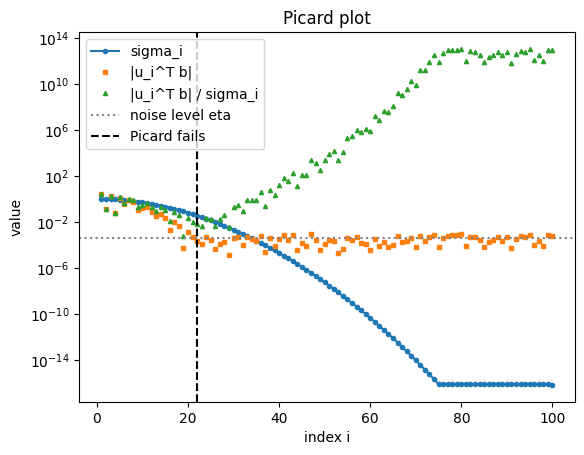

In [46]:
coef = np.abs(U.T @ b)
ratio = coef / s

k_fail = 0
while not (coef[k_fail] < eta and coef[k_fail + 1] < eta):
  k_fail += 1
print("Picard condition fails at index i =", k_fail + 1)

i = np.arange(1, n + 1)
plt.semilogy(i, s, 'o-', markersize=3, label="sigma_i")
plt.semilogy(i, coef, 's', markersize=3, label="|u_i^T b|")
plt.semilogy(i, ratio, '^', markersize=3, label="|u_i^T b| / sigma_i")
plt.axhline(eta, color='gray', linestyle=':', label="noise level eta")
plt.axvline(k_fail + 1, color='k', linestyle='--', label="Picard fails")
plt.xlabel("index i")
plt.ylabel("value")
plt.title("Picard plot")
plt.legend()
plt.show()

Once i=22 is passed, the coefficients are just noise. Dividing by small $σ_i$ causes the noise to blow up. Because of this, filtering should cut off at i=22. This add noise and keeps less signals, showing the bias-variance trad-off.

### Chapter 6 Exercise 7

naive: ||x|| = 33390522545846.492 , rel error = 8347630636461.623
TSVD: best k = 21 , rel error = 0.002200677724513622
Tikhonov: best lambda = 0.027364399970746692 , rel error = 0.003165504546931894


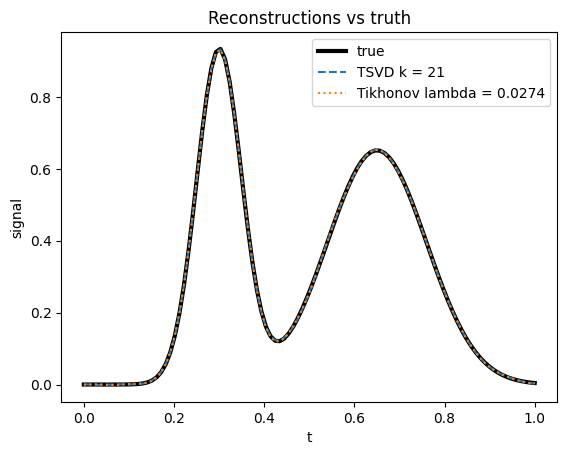

In [47]:
coef = U.T @ b

x_naive = V @ (coef / s)
print("naive: ||x|| =", np.linalg.norm(x_naive), ", rel error =", np.linalg.norm(x_naive - x_true) / np.linalg.norm(x_true))

tsvd_err = np.zeros(n)
for k in range(1, n + 1):
  xk = V[:, :k] @ (coef[:k] / s[:k])
  tsvd_err[k-1] = np.linalg.norm(xk - x_true) / np.linalg.norm(x_true)
k_best = np.argmin(tsvd_err) + 1
x_tsvd = V[:, :k_best] @ (coef[:k_best] / s[:k_best])
print("TSVD: best k =", k_best, ", rel error =", tsvd_err[k_best-1])

lams = np.logspace(-5, 1, 200)
tik_err = np.zeros(len(lams))
for i in range(len(lams)):
  f = s**2 / (s**2 + lams[i]**2)
  x_lam = V @ (f * coef / s)
  tik_err[i] = np.linalg.norm(x_lam - x_true) / np.linalg.norm(x_true)
lam_best = lams[np.argmin(tik_err)]
f = s**2 / (s**2 + lam_best**2)
x_tik = V @ (f * coef / s)
print("Tikhonov: best lambda =", lam_best, ", rel error =", np.min(tik_err))

plt.plot(t, x_true, 'k', linewidth=3, label="true")
plt.plot(t, x_tsvd, '--', label="TSVD k = " + str(k_best))
plt.plot(t, x_tik, ':', label="Tikhonov lambda = " + str(round(lam_best, 4)))
plt.xlabel("t")
plt.ylabel("signal")
plt.title("Reconstructions vs truth")
plt.legend()
plt.show()

The naive solution is large due to noise blowing up. TSVD and Tikhonov are able to fix this by filtering out small σ. The best k value is right around where Picard failed (i=22). The best balance between k and λ is found when little filtering is noisy and too much is over-smoothed.

### Chapter 6 Exercise 8

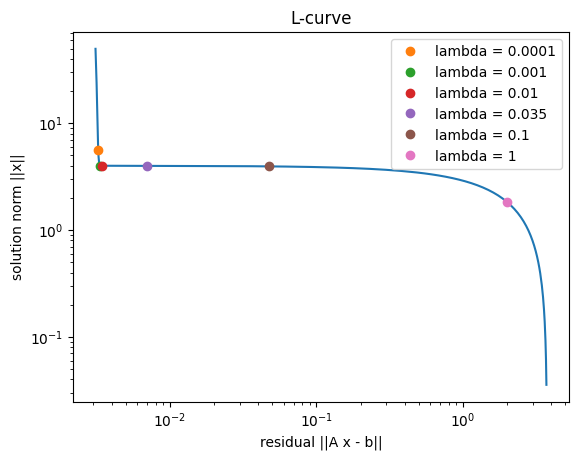

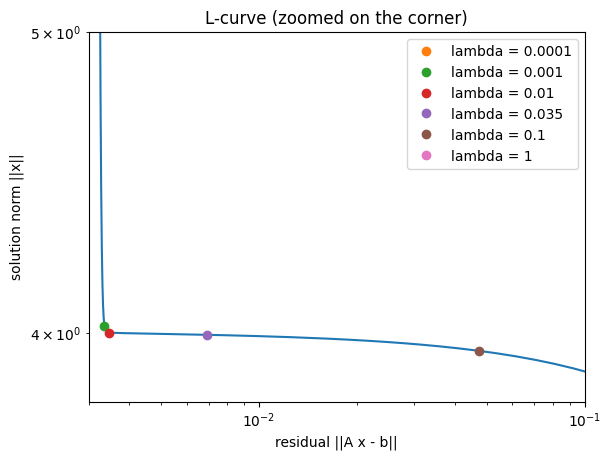

delta = 0.003718875853505015
L-curve corner:      lambda = 0.009658832241158698 , rel error = 0.006791683744364226
discrepancy princ.:  lambda = 0.016831803533309566 , rel error = 0.004177146873237201
error-optimal:       lambda = 0.027364399970746692 , rel error = 0.003165504546931894


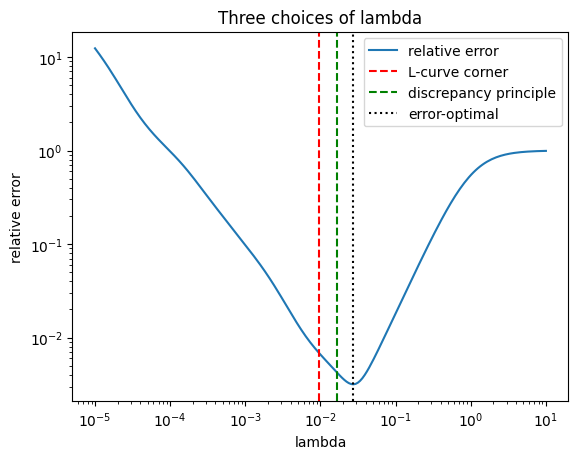

In [48]:
coef = U.T @ b

lams = np.logspace(-5, 1, 200)
res = np.zeros(len(lams))
xnorm = np.zeros(len(lams))
err = np.zeros(len(lams))
for i in range(len(lams)):
  f = s**2 / (s**2 + lams[i]**2)
  x_lam = V @ (f * coef / s)
  res[i] = np.linalg.norm(A @ x_lam - b)
  xnorm[i] = np.linalg.norm(x_lam)
  err[i] = np.linalg.norm(x_lam - x_true) / np.linalg.norm(x_true)

marks = [1e-4, 1e-3, 1e-2, 0.035, 0.1, 1]
for zoom in [False, True]:
  plt.loglog(res, xnorm, '-')
  for lam in marks:
    i = np.argmin(np.abs(lams - lam))
    plt.plot(res[i], xnorm[i], 'o', label="lambda = " + str(lam))
  if zoom:
    plt.xlim(3e-3, 1e-1)
    plt.ylim(3.8, 5)
    plt.title("L-curve (zoomed on the corner)")
  else:
    plt.title("L-curve")
  plt.xlabel("residual ||A x - b||")
  plt.ylabel("solution norm ||x||")
  plt.legend()
  plt.show()

lam_corner = 0.01
i_c = np.argmin(np.abs(lams - lam_corner))

delta = np.linalg.norm(eta * g)
i_dp = np.max(np.where(res <= delta)[0])

i_opt = np.argmin(err)

print("delta =", delta)
print("L-curve corner:      lambda =", lams[i_c], ", rel error =", err[i_c])
print("discrepancy princ.:  lambda =", lams[i_dp], ", rel error =", err[i_dp])
print("error-optimal:       lambda =", lams[i_opt], ", rel error =", err[i_opt])

plt.loglog(lams, err, label="relative error")
plt.axvline(lams[i_c], color='r', linestyle='--', label="L-curve corner")
plt.axvline(lams[i_dp], color='g', linestyle='--', label="discrepancy principle")
plt.axvline(lams[i_opt], color='k', linestyle=':', label="error-optimal")
plt.xlabel("lambda")
plt.ylabel("relative error")
plt.title("Three choices of lambda")
plt.legend()
plt.show()

At the corner where the L-curve meets the flat part, all three λ choices are close and small λ means less filtering and more noise blowing up. Larger λ means over-smoothing.

### Chapter 6 Exercise 11

lambda = 0.01  Tikhonov error = 0.0064  DI error = 0.0064
lambda = 0.1  Tikhonov error = 0.0196  DI error = 0.0045
lambda = 1  Tikhonov error = 0.5232  DI error = 0.0058
lambda = 10  Tikhonov error = 0.9909  DI error = 0.0058
lambda = 100  Tikhonov error = 0.9999  DI error = 0.0058
best DI: lambda = 0.036783797718286326 , error = 0.002621173988441112


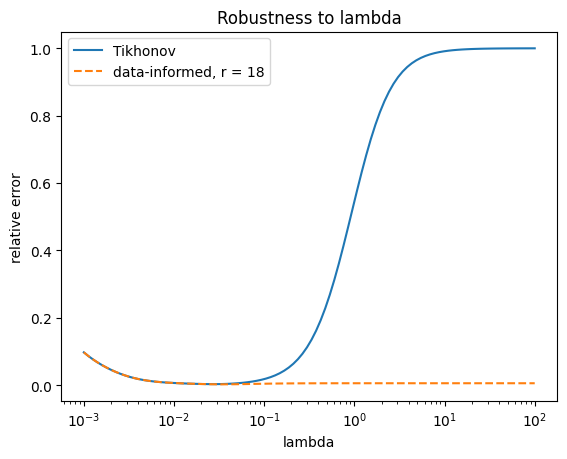

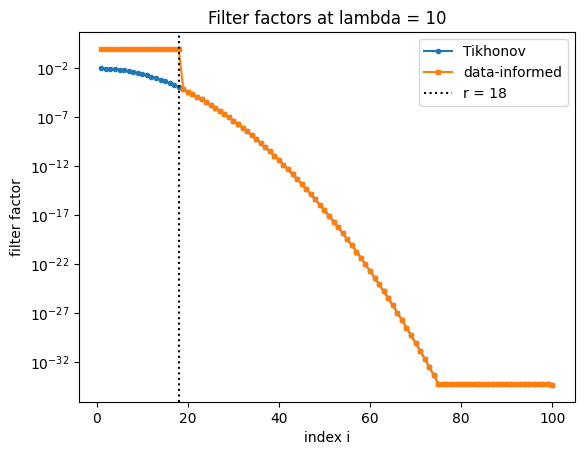

In [49]:
coef = U.T @ b
r = 18

lams = np.logspace(-3, 2, 100)
tik_err = np.zeros(len(lams))
di_err = np.zeros(len(lams))
for i in range(len(lams)):
  f_tik = s**2 / (s**2 + lams[i]**2)
  f_di = f_tik.copy()
  f_di[:r] = 1
  x_tik = V @ (f_tik * coef / s)
  x_di = V @ (f_di * coef / s)
  tik_err[i] = np.linalg.norm(x_tik - x_true) / np.linalg.norm(x_true)
  di_err[i] = np.linalg.norm(x_di - x_true) / np.linalg.norm(x_true)

for lam in [1e-2, 1e-1, 1, 10, 100]:
  i = np.argmin(np.abs(lams - lam))
  print("lambda =", lam, " Tikhonov error =", round(tik_err[i], 4), " DI error =", round(di_err[i], 4))
print("best DI: lambda =", lams[np.argmin(di_err)], ", error =", np.min(di_err))

plt.semilogx(lams, tik_err, label="Tikhonov")
plt.semilogx(lams, di_err, '--', label="data-informed, r = 18")
plt.xlabel("lambda")
plt.ylabel("relative error")
plt.title("Robustness to lambda")
plt.legend()
plt.show()

lam = 10
f_tik = s**2 / (s**2 + lam**2)
f_di = f_tik.copy()
f_di[:r] = 1
plt.semilogy(np.arange(1, n + 1), f_tik, 'o-', markersize=3, label="Tikhonov")
plt.semilogy(np.arange(1, n + 1), f_di, 's-', markersize=3, label="data-informed")
plt.axvline(r, color='k', linestyle=':', label="r = 18")
plt.xlabel("index i")
plt.ylabel("filter factor")
plt.title("Filter factors at lambda = 10")
plt.legend()
plt.show()

At large λ values, Tikhonov filter factors go to 0. This causes solutions to shrink and error to stay around 1. DI keeps the first 18 indexes at 1, so the error appears flat. Small λ causes for noise amplification.

### Chapter 6 Exercise 17

image is 128 x 128 , seed 352
Tikhonov best lambda = 0.019414919457438815 , error = 0.12342072824213458
r = 427 informed directions out of 16384
over-regularized lambda = 1.9414919457438815
Tikhonov error = 0.8019543731035038 , DI error = 0.12622819157878018


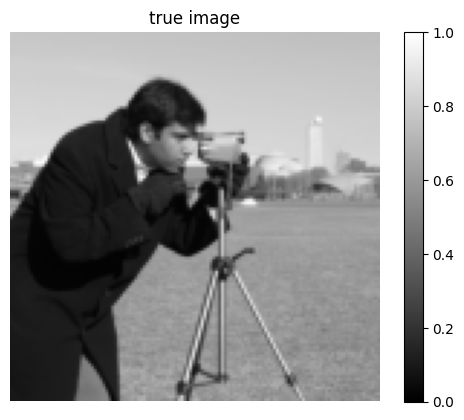

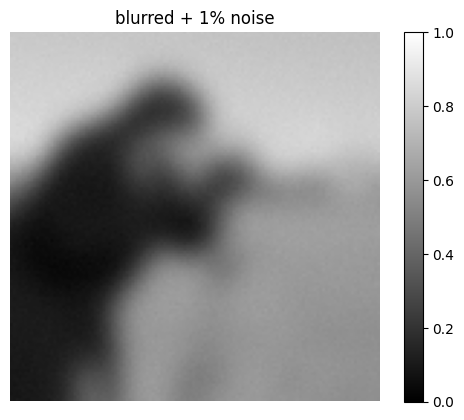

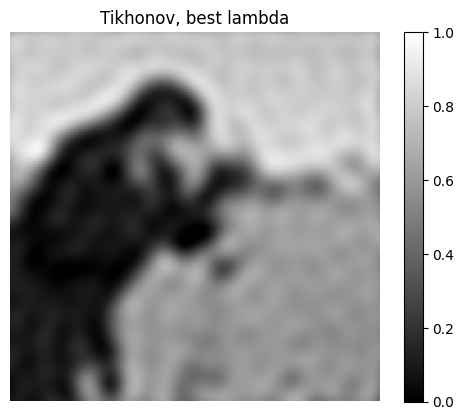

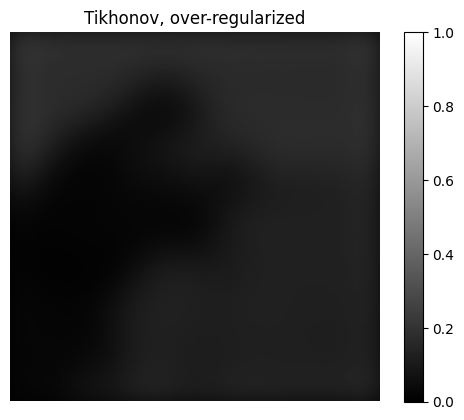

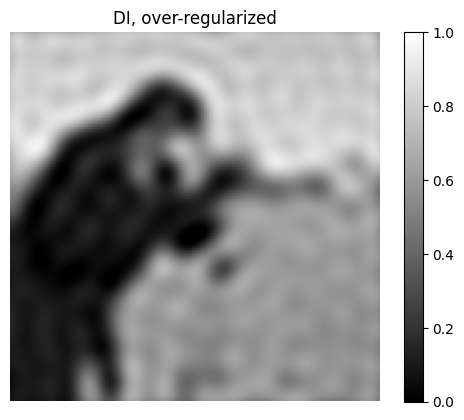

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

rng = np.random.default_rng(352)
image = resize(
    data.camera().astype(float) / 255.0,
    (128, 128),
    anti_aliasing=True,
)
m = 128
print("image is", m, "x", m, ", seed 352")

t = np.linspace(0.0, 1.0, m)
h = 0.040
G = np.zeros((m, m))
for i in range(m):
  for j in range(m):
    G[i, j] = np.exp(-(t[i] - t[j])**2 / (2*h**2))
A1 = np.zeros((m, m))
for i in range(m):
  A1[i, :] = G[i, :] / np.sum(G[i, :])

B_exact = A1 @ image @ A1.T
eta = 0.01 * np.linalg.norm(B_exact) / m
B = B_exact + eta * rng.standard_normal((m, m))

U1, s1, Vt1 = np.linalg.svd(A1)
V1 = Vt1.T
S = np.outer(s1, s1)
C = U1.T @ B @ U1

def solve(F):
  return V1 @ (F * C / S) @ V1.T

def rel_err(X):
  return np.linalg.norm(X - image) / np.linalg.norm(image)

lams = np.logspace(-4, 1, 60)
errs = np.zeros(len(lams))
for i in range(len(lams)):
  errs[i] = rel_err(solve(S**2 / (S**2 + lams[i]**2)))
lam_best = lams[np.argmin(errs)]
print("Tikhonov best lambda =", lam_best, ", error =", np.min(errs))

informed = S > lam_best
print("r =", np.sum(informed), "informed directions out of", m*m)

lam_over = 100 * lam_best
F_tik = S**2 / (S**2 + lam_over**2)
F_di = F_tik.copy()
F_di[informed] = 1

X_tik_best = solve(S**2 / (S**2 + lam_best**2))
X_tik = solve(F_tik)
X_di = solve(F_di)
print("over-regularized lambda =", lam_over)
print("Tikhonov error =", rel_err(X_tik), ", DI error =", rel_err(X_di))

pics = [image, B, X_tik_best, X_tik, X_di]
titles = ["true image", "blurred + 1% noise", "Tikhonov, best lambda",
          "Tikhonov, over-regularized", "DI, over-regularized"]
for i in range(5):
  plt.imshow(pics[i], cmap='gray', vmin=0, vmax=1)
  plt.colorbar()
  plt.title(titles[i])
  plt.axis('off')
  plt.show()

I used the same blur of h = 0.040 as in problems 3 through 11. Then I set the over-regularized λ to 100 times the best λ. With Tikhonov, I was unable to see most of the image. However, DI looked about the same as the best Tikhonov result.